<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/main/Neural_networks_multiclass_digits.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Networks (Multiclass) = Recognizing digits 0-9
#### In this file I walk through ReLU, softmax, and how to train a neural network for **more than two classes**.

The previous notebook only separated 0 from 1. Now the network must choose between **10 classes**. Two things change:
1. **Hidden layers use ReLU** instead of sigmoid.
2. **The output layer has 10 neurons and uses softmax**, giving 10 probabilities that add up to 1.

```
image (64 pixels) -> Dense(25, ReLU) -> Dense(15, ReLU) -> Dense(10, softmax) -> P(digit = 0..9)
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## ReLU
$$\text{ReLU}(z) = \max(0, z)$$
Pass positive values through, turn negative values into 0. It is cheap to compute and its gradient is 1 for positive inputs, so deep networks learn faster than with sigmoid (whose gradient gets tiny at both ends - the *vanishing gradient* problem).

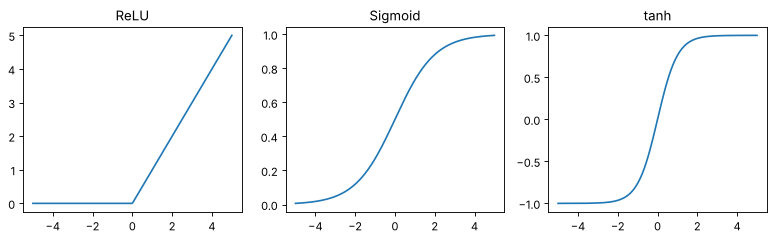

In [2]:
z = np.linspace(-5, 5, 200)
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].plot(z, np.maximum(0, z)); ax[0].set_title("ReLU")
ax[1].plot(z, 1 / (1 + np.exp(-z))); ax[1].set_title("Sigmoid")
ax[2].plot(z, np.tanh(z)); ax[2].set_title("tanh")
plt.show()

## Softmax
For $N$ classes the last layer outputs $N$ raw scores $z_1..z_N$ (called **logits**). Softmax turns them into probabilities:

$$a_j = \frac{e^{z_j}}{\sum_{k=1}^{N} e^{z_k}}$$

Every output is between 0 and 1 and they sum to 1. With 2 classes softmax becomes the sigmoid (logistic regression is the N = 2 special case).

In [3]:
def my_softmax(z):
    ez = np.exp(z)
    return ez / np.sum(ez)

z = np.array([2.0, 1.0, 0.1])
print("softmax([2, 1, 0.1]) =", my_softmax(z).round(3), "| sum =", my_softmax(z).sum())

softmax([2, 1, 0.1]) = [0.659 0.242 0.099] | sum = 1.0


### The numerical problem with a naive softmax
$e^{z}$ explodes for big $z$. With a logit of 1000, `np.exp(1000)` is `inf` and the answer is `nan`. The fix: subtract the max logit first. The result is mathematically identical because the common factor cancels.

In [4]:
big = np.array([1000.0, 1001.0, 1002.0])
print("naive  :", my_softmax(big))

def stable_softmax(z):
    e = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)

print("stable :", stable_softmax(big).round(4))

naive  : [nan nan nan]
stable : [0.09   0.2447 0.6652]


## The loss: sparse categorical cross-entropy
If the true digit is $y$ then the loss is just $-\log(a_y)$ - the negative log of the probability the network gave to the **correct** class. Confident and right: ~0. Confident and wrong: huge.

In [5]:
def cross_entropy(probs, y):
    return -np.mean(np.log(probs[np.arange(len(y)), y] + 1e-12))

print("loss when correct class gets 0.9:", -np.log(0.9).round(3))
print("loss when correct class gets 0.1:", -np.log(0.1).round(3))

loss when correct class gets 0.9: 0.105
loss when correct class gets 0.1: 2.303


## The dataset: all 10 digits

train: (1347, 64) | test: (450, 64) | classes: [0 1 2 3 4 5 6 7 8 9]


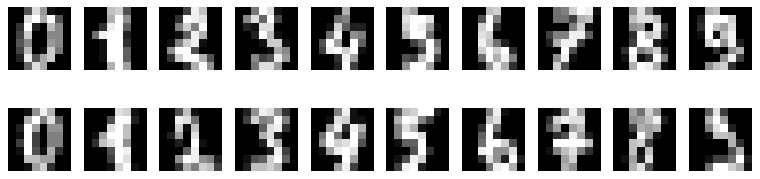

In [6]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
digits = load_digits()
X, y = digits.data / 16.0, digits.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print("train:", X_tr.shape, "| test:", X_te.shape, "| classes:", np.unique(y))

fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for d in range(10):
    for r in range(2):
        axes[r, d].imshow(X[np.where(y == d)[0][r]].reshape(8, 8), cmap="gray"); axes[r, d].axis("off")
plt.show()

## Training a neural network by hand (forward + backward pass)
In the binary notebook scikit-learn trained the weights. Here I do the whole training loop myself so I see what `model.fit` does.

**Forward**: `A1 = relu(X W1 + b1)`, `A2 = relu(A1 W2 + b2)`, `P = softmax(A2 W3 + b3)`.

**Backward**: the beautiful fact about softmax + cross-entropy is that the gradient of the loss with respect to the logits is simply **`P - Y_onehot`** (predicted probabilities minus the true one-hot vector). From there each layer passes the gradient backwards: `dW = A_prev.T @ dZ`, `dA_prev = dZ @ W.T`, and for ReLU multiply by `(Z > 0)`.

In [7]:
rng = np.random.default_rng(0)
sizes = [64, 25, 15, 10]
params = {}
for l in range(1, 4):
    params[f"W{l}"] = rng.normal(0, np.sqrt(2 / sizes[l - 1]), (sizes[l - 1], sizes[l]))      # He initialization for ReLU
    params[f"b{l}"] = np.zeros(sizes[l])

def forward(X, p):
    Z1 = X @ p["W1"] + p["b1"];  A1 = np.maximum(0, Z1)
    Z2 = A1 @ p["W2"] + p["b2"]; A2 = np.maximum(0, Z2)
    Z3 = A2 @ p["W3"] + p["b3"]; P = stable_softmax(Z3)
    return (Z1, A1, Z2, A2, Z3), P

def backward(X, y, cache, P, p):
    Z1, A1, Z2, A2, Z3 = cache
    m = len(y)
    dZ3 = P.copy(); dZ3[np.arange(m), y] -= 1; dZ3 /= m           # P - one_hot(y), averaged over the batch
    g = {"W3": A2.T @ dZ3, "b3": dZ3.sum(0)}
    dZ2 = (dZ3 @ p["W3"].T) * (Z2 > 0)
    g.update({"W2": A1.T @ dZ2, "b2": dZ2.sum(0)})
    dZ1 = (dZ2 @ p["W2"].T) * (Z1 > 0)
    g.update({"W1": X.T @ dZ1, "b1": dZ1.sum(0)})
    return g

Gradient check on a few weights first (compare with a numerical derivative):

In [8]:
cache, P = forward(X_tr[:32], params)
g = backward(X_tr[:32], y_tr[:32], cache, P, params)
def loss_at(): return cross_entropy(forward(X_tr[:32], params)[1], y_tr[:32])
biggest = tuple(int(i) for i in np.unravel_index(np.abs(g["W1"]).argmax(), g["W1"].shape))      # a weight that actually has a non-zero gradient
for name, idx in [("W1", biggest), ("W2", (4, 7)), ("W3", (2, 9)), ("b3", (5,))]:
    eps = 1e-6; old = params[name][idx]
    params[name][idx] = old + eps; hi = loss_at()
    params[name][idx] = old - eps; lo = loss_at()
    params[name][idx] = old
    print(f"{name}{idx}: backprop {g[name][idx]: .3e} | numeric {(hi - lo) / (2 * eps): .3e}")

W1(4, 0): backprop  2.389e-01 | numeric  2.389e-01
W2(4, 7): backprop  6.673e-02 | numeric  6.673e-02
W3(2, 9): backprop -1.459e-02 | numeric -1.459e-02
b3(5,): backprop  1.078e-02 | numeric  1.078e-02


epoch   0: train loss 2.1828 | test loss 2.1789 | test accuracy 0.204
epoch  50: train loss 0.3370 | test loss 0.5076 | test accuracy 0.878
epoch 100: train loss 0.0195 | test loss 0.1325 | test accuracy 0.969
epoch 150: train loss 0.0081 | test loss 0.1399 | test accuracy 0.971
epoch 200: train loss 0.0048 | test loss 0.1605 | test accuracy 0.962
epoch 250: train loss 0.0069 | test loss 0.1841 | test accuracy 0.962
epoch 299: train loss 0.0023 | test loss 0.1654 | test accuracy 0.964


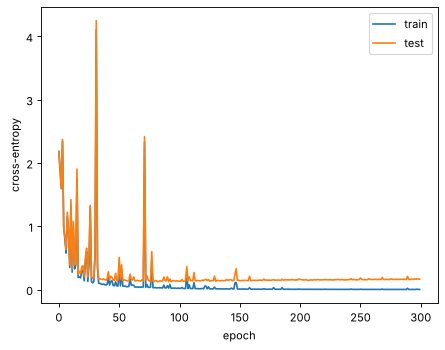

In [9]:
lr = 0.1
train_loss, test_loss, test_acc = [], [], []
for epoch in range(300):
    order = rng.permutation(len(y_tr))
    for s in range(0, len(order), 64):                      # mini-batch gradient descent, batch size 64
        b = order[s:s + 64]
        cache, P = forward(X_tr[b], params)
        grads = backward(X_tr[b], y_tr[b], cache, P, params)
        for k in params: params[k] -= lr * grads[k]
    train_loss.append(cross_entropy(forward(X_tr, params)[1], y_tr))
    Pt = forward(X_te, params)[1]
    test_loss.append(cross_entropy(Pt, y_te)); test_acc.append(np.mean(Pt.argmax(1) == y_te))
    if epoch % 50 == 0 or epoch == 299:
        print(f"epoch {epoch:3d}: train loss {train_loss[-1]:.4f} | test loss {test_loss[-1]:.4f} | test accuracy {test_acc[-1]:.3f}")

plt.plot(train_loss, label="train"); plt.plot(test_loss, label="test"); plt.xlabel("epoch"); plt.ylabel("cross-entropy"); plt.legend(); plt.show()

Look at the curves: the train loss keeps falling towards 0 but the **test loss bottoms out around epoch 100 and then creeps up**. That is the start of overfitting - the network is memorizing the training set. Stopping early (or adding regularization) would be better than training all 300 epochs.

## Where does it get confused?
A confusion matrix shows, for each true digit (rows), what the network predicted (columns). Everything off the diagonal is a mistake.

test accuracy: 0.9644


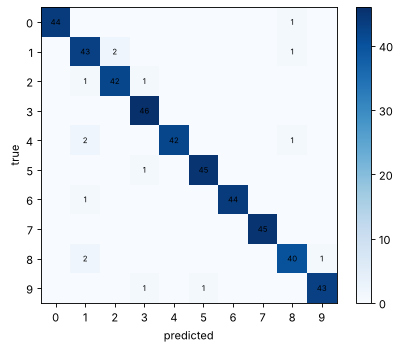

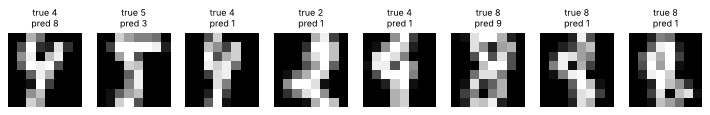

In [10]:
from sklearn.metrics import confusion_matrix
pred = forward(X_te, params)[1].argmax(1)
cm = confusion_matrix(y_te, pred)
plt.imshow(cm, cmap="Blues"); plt.colorbar()
for i in range(10):
    for j in range(10):
        if cm[i, j]: plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
plt.xlabel("predicted"); plt.ylabel("true"); plt.xticks(range(10)); plt.yticks(range(10)); plt.show()

wrong = np.where(pred != y_te)[0][:8]
fig, axes = plt.subplots(1, len(wrong), figsize=(1.4 * len(wrong), 1.8))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray"); ax.set_title(f"true {y_te[i]}\npred {pred[i]}", fontsize=8); ax.axis("off")
plt.show()
print("test accuracy:", np.mean(pred == y_te).round(4))

## The scikit-learn version

In [11]:
from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(hidden_layer_sizes=(25, 15), activation="relu", max_iter=500, random_state=0).fit(X_tr, y_tr)
print("sklearn MLPClassifier test accuracy:", round(mlp.score(X_te, y_te), 4))

sklearn MLPClassifier test accuracy: 0.9711


## The Keras version and "softmax placement"
In the course lab, the first model puts `softmax` in the last Dense layer and trains with `SparseCategoricalCrossentropy()`. That works, but the network has to compute softmax and *then* the log of it, which loses precision (tiny probabilities round to 0).

The **recommended** way: make the last layer **linear** (outputs logits) and tell the loss `from_logits=True`. TensorFlow then combines softmax and the loss into one numerically stable computation - the same trick as my `stable_softmax` above. The price: the model outputs logits, so apply softmax myself when I want probabilities.

**I could not run this cell where I prepared this notebook (no TensorFlow) - run it in Colab.**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

preferred_model = Sequential([
    tf.keras.Input(shape=(64,)),
    Dense(25, activation="relu"),
    Dense(15, activation="relu"),
    Dense(10, activation="linear"),                  # logits, NOT probabilities
])
preferred_model.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                        optimizer=tf.keras.optimizers.Adam(0.001))
preferred_model.fit(X_tr, y_tr, epochs=100, verbose=0)

logits = preferred_model.predict(X_te)
probs = tf.nn.softmax(logits).numpy()                # convert to probabilities only at prediction time
print("Keras test accuracy:", (probs.argmax(1) == y_te).mean())

## Drawbacks / things to remember
- **Softmax outputs sum to 1**, so it forces exactly one answer. If an image can have several labels (multi-label), use sigmoid outputs instead of softmax.
- **Always compute softmax + loss together** (`from_logits=True`) to avoid numerical issues.
- **Initialization matters**: with all-zero weights every neuron in a layer learns the same thing. Random (He) initialization breaks the symmetry.
- **Dead ReLUs**: a neuron whose input is always negative outputs 0 and gets no gradient. A smaller learning rate or LeakyReLU can help.
- Data is tiny and clean (8x8); real handwriting needs bigger networks - preferably convolutional - and regularization/validation to avoid overfitting.